In [1]:
!pip install -q sentence-transformers datasets

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [23]:
# STEP 1: DOWNLOAD, READ & CLEAN DATASET

print("=" * 60)
print("STEP 1: DATA INGESTION & CLEANING")
print("=" * 60)

dataset = load_dataset("PolyAI/banking77", split="test")
raw_filename = "raw_customer_tickets.csv"
pd.DataFrame({"Message": dataset["text"][:300]}).to_csv(raw_filename, index=False)

# Explicitly read dataset using Pandas
df = pd.read_csv(raw_filename)
print(f"Raw rows loaded from '{raw_filename}': {len(df)}")
print("\nFirst 5 raw rows:")
print(df.head().to_string(index=False))

# Clean: strip extra whitespace, drop short noise, and remove exact duplicates
df["Message"] = df["Message"].astype(str).str.strip()
df = df[df["Message"].str.len() > 5].drop_duplicates().reset_index(drop=True)
print(f"\nClean rows remaining after removing duplicates/noise: {len(df)}\n")

STEP 1: DATA INGESTION & CLEANING
Raw rows loaded from 'raw_customer_tickets.csv': 300

First 5 raw rows:
                                                          Message
                                         How do I locate my card?
I still have not received my new card, I ordered over a week ago.
            I ordered a card but it has not arrived. Help please!
                 Is there a way to know when my card will arrive?
                                     My card has not arrived yet.

Clean rows remaining after removing duplicates/noise: 300



In [24]:
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA)

print("=" * 60)
print("STEP 2: EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 60)

df["Word_Count"] = df["Message"].apply(lambda x: len(x.split()))
df["Char_Count"] = df["Message"].apply(len)

eda_summary = pd.DataFrame({
    "Metric": ["Total Clean Tickets", "Avg Word Count", "Shortest Ticket (Words)", "Longest Ticket (Words)"],
    "Value": [
        len(df),
        round(df["Word_Count"].mean(), 1),
        df["Word_Count"].min(),
        df["Word_Count"].max()
    ]
})
print(eda_summary.to_string(index=False), "\n")

STEP 2: EXPLORATORY DATA ANALYSIS (EDA)
                 Metric  Value
    Total Clean Tickets  300.0
         Avg Word Count   11.0
Shortest Ticket (Words)    4.0
 Longest Ticket (Words)   47.0 



In [25]:
# STEP 3: FEATURE ENGINEERING (TEXT -> VECTORS)

print("=" * 60)
print("STEP 3: FEATURE ENGINEERING (SENTENCE EMBEDDINGS)")
print("=" * 60)

embedder = SentenceTransformer("all-MiniLM-L6-v2")
X_embeddings = embedder.encode(df["Message"].tolist(), normalize_embeddings=True)

print(f"Converted {X_embeddings.shape[0]} messages into {X_embeddings.shape[1]}-dimensional meaning vectors.")
print(f"Sample vector preview (first 5 numbers for Ticket #1): {X_embeddings[0][:5].round(3)}\n")

STEP 3: FEATURE ENGINEERING (SENTENCE EMBEDDINGS)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Converted 300 messages into 384-dimensional meaning vectors.
Sample vector preview (first 5 numbers for Ticket #1): [-0.01   0.019 -0.058  0.016  0.024]



In [26]:
# STEP 4: UNSUPERVISED ROOT-CAUSE DISCOVERY

print("=" * 60)
print("STEP 4: UNSUPERVISED ROOT-CAUSE DISCOVERY")
print("=" * 60)

clustering = AgglomerativeClustering(
    n_clusters=None, metric="cosine", linkage="average", distance_threshold=0.55
)
df["Cluster_ID"] = clustering.fit_predict(X_embeddings)

# Auto-label clusters using top 3 descriptive words
labeler = TfidfVectorizer(stop_words="english", max_features=500)
tfidf = labeler.fit_transform(df["Message"])
words = labeler.get_feature_names_out()

cluster_names = {}
for cid in df["Cluster_ID"].unique():
    idx = df[df["Cluster_ID"] == cid].index
    top_idx = tfidf[idx].mean(axis=0).A1.argsort()[::-1][:3]
    cluster_names[cid] = " / ".join([words[i] for i in top_idx]).upper()

df["Problem_Theme"] = df["Cluster_ID"].map(cluster_names)

cluster_summary = (
    df.groupby("Problem_Theme")
    .size()
    .reset_index(name="Ticket_Count")
    .sort_values(by="Ticket_Count", ascending=False)
)
print(f"Discovered {df['Cluster_ID'].nunique()} distinct problem groups. Top 5 largest themes:")
print(cluster_summary.head(5).to_string(index=False), "\n")

STEP 4: UNSUPERVISED ROOT-CAUSE DISCOVERY
Discovered 15 distinct problem groups. Top 5 largest themes:
               Problem_Theme  Ticket_Count
           CARD / LINK / NEW            89
     EXCHANGE / RATE / RATES            77
 PENDING / CASH / WITHDRAWAL            40
CURRENCIES / FIAT / CURRENCY            39
     STATEMENT / FEE / EXTRA            34 



In [27]:
# STEP 5: MODEL TRAINING & VALIDATION

print("=" * 60)
print("STEP 5: PREDICTIVE MODEL TRAINING & EVALUATION")
print("=" * 60)

# Keep themes with >= 4 tickets for a balanced 80/20 train/test split
valid_themes = df["Problem_Theme"].value_counts()
valid_themes = valid_themes[valid_themes >= 4].index
model_df = df[df["Problem_Theme"].isin(valid_themes)].copy()

X_model = embedder.encode(model_df["Message"].tolist(), normalize_embeddings=True)
y_model = model_df["Problem_Theme"]

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.2, random_state=42, stratify=y_model
)

predictor = LogisticRegression(max_iter=1000)
predictor.fit(X_train, y_train)

y_pred_test = predictor.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"Training set size: {len(X_train)} tickets | Validation test set size: {len(X_test)} tickets")
print(f"Validation Accuracy on unseen test tickets: {test_accuracy * 100:.1f}%\n")

STEP 5: PREDICTIVE MODEL TRAINING & EVALUATION
Training set size: 230 tickets | Validation test set size: 58 tickets
Validation Accuracy on unseen test tickets: 100.0%



In [28]:
# STEP 6: LIVE PREDICTION + BUSINESS GUARDRAIL

print("=" * 60)
print("STEP 6: LIVE PREDICTION & CONFIDENCE GUARDRAIL")
print("=" * 60)

new_tickets = [
    "I tried paying at the grocery store but my card got rejected twice.",
    "Why is my bank transfer still pending after three days?",
    "Someone used my card in another city without my permission!",
    "My cat walked across my keyboard and ordered a toaster."  # Off-topic edge case
]

new_vecs = embedder.encode(new_tickets, normalize_embeddings=True)
preds = predictor.predict(new_vecs)
probs = predictor.predict_proba(new_vecs).max(axis=1)

live_results = pd.DataFrame({
    "New_Ticket": new_tickets,
    "Predicted_Route": preds,
    "Confidence_%": (probs * 100).round(1),
    "Action": ["Auto-Route" if p >= 0.45 else "Human Review" for p in probs]
})
print(live_results.to_string(index=False), "\n")

STEP 6: LIVE PREDICTION & CONFIDENCE GUARDRAIL
                                                         New_Ticket             Predicted_Route  Confidence_%       Action
I tried paying at the grocery store but my card got rejected twice.           CARD / LINK / NEW          56.4   Auto-Route
            Why is my bank transfer still pending after three days? PENDING / CASH / WITHDRAWAL          65.1   Auto-Route
        Someone used my card in another city without my permission!           CARD / LINK / NEW          67.0   Auto-Route
            My cat walked across my keyboard and ordered a toaster.           CARD / LINK / NEW          39.8 Human Review 



STEP 7: GENERATING EXECUTIVE DASHBOARD VISUALIZATION


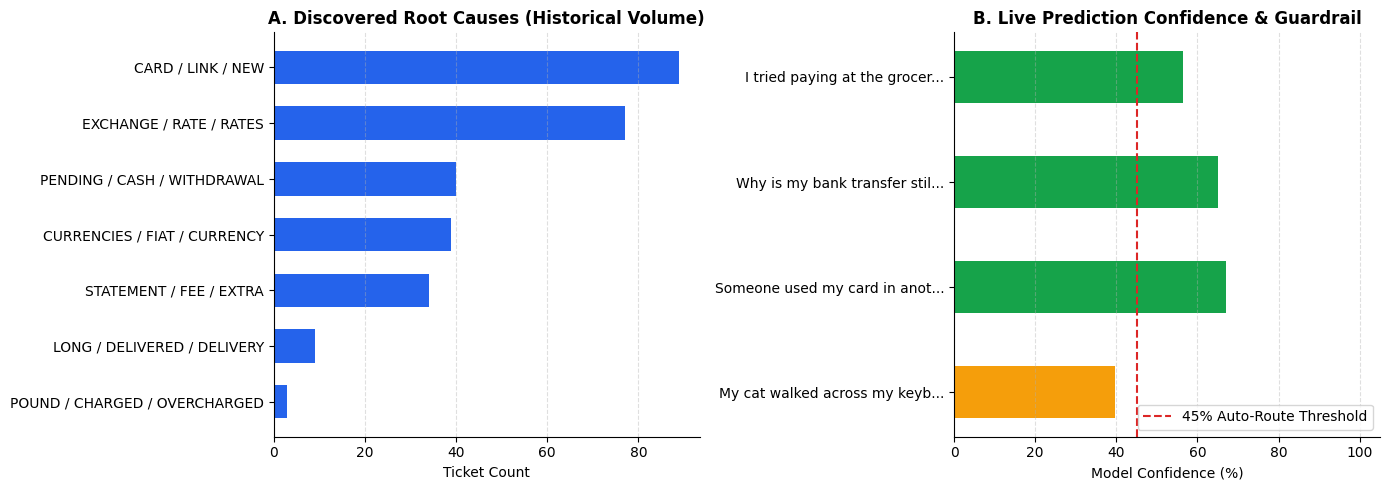

Dashboard rendered above.



In [29]:
# STEP 7: 2-PANEL EXECUTIVE VISUALIZATION

print("=" * 60)
print("STEP 7: GENERATING EXECUTIVE DASHBOARD VISUALIZATION")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Top Discovered Root Causes (Volume)
top_issues = df["Problem_Theme"].value_counts().head(7).iloc[::-1]
axes[0].barh(top_issues.index, top_issues.values, color="#2563eb", height=0.6)
axes[0].set_title("A. Discovered Root Causes (Historical Volume)", fontweight="bold")
axes[0].set_xlabel("Ticket Count")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel B: Live Ticket Confidence vs. Human-Review Threshold
bar_colors = ["#16a34a" if c >= 45 else "#f59e0b" for c in live_results["Confidence_%"]]
short_labels = [t[:28] + "..." for t in live_results["New_Ticket"]]

axes[1].barh(short_labels[::-1], live_results["Confidence_%"][::-1], color=bar_colors[::-1], height=0.5)
axes[1].axvline(45, color="#dc2626", linestyle="--", linewidth=1.5, label="45% Auto-Route Threshold")
axes[1].set_xlim(0, 105)
axes[1].set_title("B. Live Prediction Confidence & Guardrail", fontweight="bold")
axes[1].set_xlabel("Model Confidence (%)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
print("Dashboard rendered above.\n")


In [30]:
# STEP 8: EXPORT CLEAN CSV DELIVERABLES

print("=" * 60)
print("STEP 8: EXPORTING CLEAN CSV REPORTS")
print("=" * 60)

historical_file = "clustered_historical_tickets.csv"
predictions_file = "live_ticket_predictions.csv"

df[["Cluster_ID", "Problem_Theme", "Word_Count", "Message"]].to_csv(historical_file, index=False)
live_results.to_csv(predictions_file, index=False)

print(f"Saved '{historical_file}' ({len(df)} rows) -> Preview:")
print(pd.read_csv(historical_file).head(3).to_string(index=False))

print(f"\nSaved '{predictions_file}' ({len(live_results)} rows) -> Preview:")
print(pd.read_csv(predictions_file).to_string(index=False))

try:
  from google.colab import files
  files.download(historical_file)
  files.download(predictions_file)
except ImportError:
  print("\n(Running locally: CSV files saved in your current working directory.)")

STEP 8: EXPORTING CLEAN CSV REPORTS
Saved 'clustered_historical_tickets.csv' (300 rows) -> Preview:
 Cluster_ID     Problem_Theme  Word_Count                                                           Message
          4 CARD / LINK / NEW           6                                          How do I locate my card?
          4 CARD / LINK / NEW          14 I still have not received my new card, I ordered over a week ago.
          4 CARD / LINK / NEW          11             I ordered a card but it has not arrived. Help please!

Saved 'live_ticket_predictions.csv' (4 rows) -> Preview:
                                                         New_Ticket             Predicted_Route  Confidence_%       Action
I tried paying at the grocery store but my card got rejected twice.           CARD / LINK / NEW          56.4   Auto-Route
            Why is my bank transfer still pending after three days? PENDING / CASH / WITHDRAWAL          65.1   Auto-Route
        Someone used my card in another c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>